# BERT y aprendizaje semi-supervisado para clasificar textos
## Data Mining - Doctorado UDP 2026
**Dr. Bastián González-Bustamante, Profesor Asociado** \
Noviembre 2026

[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Doctorado-UDP/data-mining-2026/blob/main/code/5_BERT_y_semisupervision.ipynb)

**Sesión 13 · jueves 19 de noviembre de 2026 · Parte 2: demostración (1 de 2).**

Seguimos con el mismo problema de la Sesión 12: ¿es tóxico este mensaje? En S12 usamos TF-IDF y modelos lineales. Hoy probamos dos ideas de la presentación:
- **modelos tipo BERT ya ajustados** (*fine-tuned*) para toxicidad en español, que solo usamos para predecir (inferencia): no los volvemos a entrenar;
- **aprendizaje semi-supervisado y activo**: ¿qué pasa si solo tenemos etiquetas para una pequeña parte de los mensajes?

El segundo notebook de la sesión, `6_LLM_clasificador.ipynb`, clasifica los mismos mensajes con un LLM local (Ollama).

| N.º | Sección | Presentación |
|---|---|---|
| 1 | Datos y línea base de S12 | Repaso S12 |
| 2 | BERT y RoBERTa ya ajustados: subpalabras, inferencia y validación fuera del dominio | BERT y RoBERTa para clasificar |
| 3 | Pocas etiquetas: auto-entrenamiento (*self-training*) y aprendizaje activo | Aprendizaje semi-supervisado; aprendizaje activo |
| 4 | Ejercicios | No aplica |

**Cómo usarlo.**
- Las celdas precedidas por **▶ En vivo** se ejecutan durante la clase.
- La primera vez, la sección 2 **descarga tres modelos de Hugging Face (unos 2 GB en total)**. En Colab tarda poco; en su computador puede tardar varios minutos según la conexión. Después quedan en caché.
- La inferencia corre en la CPU. Todo el notebook tarda unos 5 a 10 minutos en un computador portátil o en Colab sin GPU (con GPU, "Entorno de ejecución → Cambiar tipo de entorno", mucho menos).
- `random_state=86` en todos los pasos aleatorios. Usamos la **misma partición** de S12, para comparar.

**Advertencia de contenido:** algunos mensajes contienen lenguaje ofensivo.

### Entorno: local o Google Colab

Este notebook corre en su computador y en Google Colab. La primera celda de código detecta dónde se ejecuta:
- **En Google Colab** instala solo los paquetes que falten (en esta sesión, ninguno: Colab trae `transformers` y `torch`), sin actualizar los preinstalados, así que no hace falta reiniciar la sesión. Para conservar sus cambios, use "Archivo → Guardar una copia en Drive".
- **En su computador** no instala nada: cree antes un entorno virtual con `pip install -r requirements.txt`, que incluye `torch` (versión para CPU) y `transformers`.

Luego muestra las versiones instaladas y verifica que estén en el rango soportado: Python ≥ 3.11, scikit-learn ≥ 1.6, pandas ≥ 2.2, NumPy ≥ 2.0, PyTorch ≥ 2.2 y Transformers ≥ 4.45.

In [1]:
## Entorno: detectar Google Colab, instalar solo lo que falte y verificar las versiones
import re
import sys
from importlib import invalidate_caches
from importlib.metadata import version
from importlib.util import find_spec

## Paquetes que usa este notebook: {módulo: (nombre en pip, versión mínima soportada)}
PAQUETES = {
    "sklearn": ("scikit-learn", "1.6"),
    "pandas": ("pandas", "2.2"),
    "numpy": ("numpy", "2.0"),
    "matplotlib": ("matplotlib", "3.9"),
    "nltk": ("nltk", "3.8"),
    "torch": ("torch", "2.2"),
    "transformers": ("transformers", "4.45"),
}

EN_COLAB = "google.colab" in sys.modules
faltan = [pip for modulo, (pip, _) in PAQUETES.items() if find_spec(modulo) is None]
if faltan and EN_COLAB:
    ## En Colab se instalan solo los paquetes que faltan; los preinstalados no se actualizan
    get_ipython().run_line_magic("pip", "install -q " + " ".join(faltan))
    invalidate_caches()
    faltan = []
## En su computador no se instala nada: el entorno virtual se crea con requirements.txt
assert not faltan, f"Faltan paquetes: {', '.join(faltan)}. Instálelos con pip install -r requirements.txt."


def version_al_menos(paquete, minima):
    ## Compara los dos primeros números de la versión instalada con la mínima (p. ej., "1.6.1" >= "1.6")
    actual = tuple(int(n) for n in re.findall(r"\d+", version(paquete))[:2])
    return actual >= tuple(int(n) for n in minima.split("."))


print(f"Python {sys.version.split()[0]} | "
      + " | ".join(f"{pip} {version(pip)}" for pip, _ in PAQUETES.values())
      + (" | Google Colab" if EN_COLAB else " | computador local"))
assert sys.version_info >= (3, 11), "Este notebook requiere Python 3.11 o superior."
antiguos = [f"{pip} {version(pip)} (mínimo {minima})" for pip, minima in PAQUETES.values()
            if not version_al_menos(pip, minima)]
assert not antiguos, f"Versiones no soportadas: {'; '.join(antiguos)}. Actualice esos paquetes en su entorno."

Python 3.12.7 | scikit-learn 1.9.1 | pandas 3.0.6 | numpy 2.5.4 | matplotlib 3.11.2 | nltk 3.10.3 | torch 2.11.0+cpu | transformers 5.18.0 | computador local


In [2]:
## Importar librerías necesarias
import os
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import sklearn
import torch
import transformers
from transformers import pipeline, AutoTokenizer
from nltk.stem import SnowballStemmer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.semi_supervised import SelfTrainingClassifier
from sklearn.metrics import f1_score, cohen_kappa_score

## Menos mensajes de Transformers y de Hugging Face (barras de progreso y avisos informativos)
transformers.logging.set_verbosity_error()
transformers.utils.logging.disable_progress_bar()
os.environ.setdefault("HF_HUB_DISABLE_PROGRESS_BARS", "1")

## Hilos de la CPU para PyTorch (como en S10: no más de 8)
torch.set_num_threads(min(8, os.cpu_count()))
DISPOSITIVO = 0 if torch.cuda.is_available() else -1  # GPU si existe (por ejemplo, en Colab con GPU)

print(f"pandas {pd.__version__} | numpy {np.__version__} | scikit-learn {sklearn.__version__} | "
      f"torch {torch.__version__} | transformers {transformers.__version__} | "
      f"{'GPU' if DISPOSITIVO == 0 else 'CPU'} ({torch.get_num_threads()} hilos)")

pandas 3.0.6 | numpy 2.5.4 | scikit-learn 1.9.1 | torch 2.11.0+cpu | transformers 5.18.0 | CPU (8 hilos)


In [3]:
## Estilo de los gráficos (el mismo de S8 a S12)
plt.rcParams.update({
    "figure.dpi": 100,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.titlesize": 11,
    "axes.labelsize": 10,
})
AZUL, NARANJA, VERDE, GRIS = "#2a78d6", "#eb6834", "#1baf7a", "#8a8984"

## 1. Datos y línea base de S12

**▶ En vivo.** Cargamos los dos patrones oro de S12 (Hugging Face, CC BY 4.0) y repetimos la **misma partición** 80/20, estratificada por etiqueta y país, con `random_state=86`. La etiqueta es `coder_1`; `coder_2` es la referencia humana.

Para el conjunto de la **Convención Constitucional** usamos una muestra estratificada de 500 mensajes, para que la inferencia en CPU no tarde demasiado. Pueden usar los 1.000 cambiando `N_CONVENCION`.

In [4]:
## Cargar los dos patrones oro y repetir la partición de S12
URL_HF = "https://huggingface.co/datasets/bgonzalezbustamante/{}/resolve/main/{}"
protestas = pd.read_csv(URL_HF.format("toxicity-protests-ES", "goldstd_protests.csv"))
convencion_completa = pd.read_csv(URL_HF.format("toxicity-Constitution-ES", "goldstd_Convention.csv"))

y = protestas["coder_1"].to_numpy()
estratos = protestas["coder_1"].astype(str) + "_" + protestas["country"]
idx_train, idx_test = train_test_split(np.arange(len(protestas)), test_size=0.20,
                                       stratify=estratos, random_state=86)
y_train, y_test = y[idx_train], y[idx_test]

N_CONVENCION = 500
convencion = (convencion_completa if N_CONVENCION >= len(convencion_completa) else
              convencion_completa.groupby("coder_1", group_keys=False)
              .sample(frac=N_CONVENCION / len(convencion_completa), random_state=86))
y_conv = convencion["coder_1"].to_numpy()

print(f"Protestas: entrenamiento {len(idx_train)} | prueba {len(idx_test)}")
print(f"Convención: {len(convencion)} mensajes (de {len(convencion_completa)}); tóxicos {y_conv.mean():.1%}")

Protestas: entrenamiento 800 | prueba 200
Convención: 500 mensajes (de 1000); tóxicos 65.2%


In [5]:
## Línea base de S12: TF-IDF sobre raíces de Snowball + regresión logística (la mejor configuración de S12)
snowball = SnowballStemmer("spanish")


def normalizar(texto):
    ## Igual que en S12: menciones -> @usuario; sin enlaces ni "#"; minúsculas
    texto = re.sub(r"https?://\S+", " ", texto)
    texto = re.sub(r"@\w+", " @usuario ", texto)
    texto = texto.replace("#", " ")
    return re.sub(r"\s+", " ", texto).strip().lower()


def raices(textos):
    return [" ".join(snowball.stem(p) for p in re.findall(r"\w+", normalizar(t))) for t in textos]


R_train = np.array(raices(protestas["text"].iloc[idx_train]))
R_test = np.array(raices(protestas["text"].iloc[idx_test]))
R_conv = np.array(raices(convencion["text"]))


def modelo_tfidf(**kw):
    return Pipeline([("tfidf", TfidfVectorizer(sublinear_tf=True)),
                     ("modelo", LogisticRegression(C=3.2, max_iter=2000, random_state=86, **kw))])


tfidf = modelo_tfidf().fit(R_train, y_train)
resultados = [{
    "modelo": "TF-IDF + regresión logística (S12)",
    "F1 macro, protestas (prueba)": f1_score(y_test, tfidf.predict(R_test), average="macro"),
    "F1 macro, Convención": f1_score(y_conv, tfidf.predict(R_conv), average="macro"),
}]
pd.DataFrame(resultados).round(3)

,modelo,"F1 macro, protestas (prueba)","F1 macro, Convención"
0,TF-IDF + regresión logística (S12),0.805,0.696


**Para recordar.** Esta es la vara: un modelo lineal sobre TF-IDF, entrenado con 800 mensajes etiquetados. La tokenización de esta versión es más simple que la de S12 (sin spaCy), así que los números pueden diferir en algunas milésimas de los de S12.

## 2. BERT y RoBERTa ya ajustados para toxicidad

Usamos tres modelos del profesor, publicados en Hugging Face, que ya fueron ajustados (*fine-tuned*) para clasificar toxicidad:

| Modelo | Modelo base | Parámetros | Descarga |
|---|---|---|---|
| `bgonzalezbustamante/bert-spanish-toxicity` | BETO (BERT en español) | ≈ 110 millones | ≈ 440 MB |
| `bgonzalezbustamante/ft-roberta-toxicity` | RoBERTa de Twitter (sentimiento) | ≈ 125 millones | ≈ 500 MB |
| `bgonzalezbustamante/ft-xlm-roberta-toxicity` | XLM-RoBERTa base (multilingüe) | ≈ 278 millones | ≈ 1,1 GB |

**Cuidado con la fuga de datos (S9).** Las fichas de estos modelos enlazan el mismo patrón oro de protestas como datos de ajuste. Es probable, entonces, que los mensajes de nuestra prueba **hayan estado en su entrenamiento**: su desempeño en protestas estará **inflado**. La comparación justa es la del conjunto de la **Convención**, que ninguno de los modelos vio.

### 2.1 Subpalabras

**▶ En vivo.** BERT no usa palabras completas: divide las palabras poco frecuentes en **subpalabras** (*WordPiece*, en BERT), con un vocabulario de unas 31.000 unidades en BETO.

In [6]:
## Tokenización en subpalabras del modelo BETO ajustado
tokenizador = AutoTokenizer.from_pretrained("bgonzalezbustamante/bert-spanish-toxicity")
frase = "¡No al alza del pasaje! @usuario dámelo ya, son 30 pesos #ChileDesperto"
print(f"Vocabulario: {tokenizador.vocab_size:,} unidades")
print(tokenizador.tokenize(frase))

Vocabulario: 31,002 unidades
['¡', 'No', 'al', 'alza', 'del', 'pasaje', '!', '@', 'usuario', 'dá', '##melo', 'ya', ',', 'son', '30', 'pesos', '[UNK]', 'Chile', '##D', '##esper', '##to']


**Para recordar.** Las palabras frecuentes quedan enteras; las raras se dividen en fragmentos marcados con `##`. Así el modelo nunca encuentra una palabra "desconocida", y las variantes de una palabra comparten fragmentos. Antes de clasificar, el modelo agrega un token especial `[CLS]` al inicio: su representación final es la que usa la capa de clasificación.

### 2.2 Inferencia y validación

**▶ En vivo.** `pipeline("text-classification")` reúne el tokenizador y el modelo. Lo aplicamos a la prueba de protestas y a la muestra de la Convención. Cada modelo devuelve una etiqueta (`TOXIC` o `NONTOXIC`), que convertimos con un **diccionario explícito**, verificado contra la configuración del modelo.

In [7]:
## Inferencia con los tres modelos (CPU por defecto; GPU si existe)
MODELOS = ["bgonzalezbustamante/bert-spanish-toxicity",
           "bgonzalezbustamante/ft-roberta-toxicity",
           "bgonzalezbustamante/ft-xlm-roberta-toxicity"]
ETIQUETAS = {"NONTOXIC": 0, "TOXIC": 1}

textos_test = protestas["text"].iloc[idx_test].tolist()
textos_conv = convencion["text"].tolist()
predicciones = {}
for nombre in MODELOS:
    inicio = time.perf_counter()
    clasificador = pipeline("text-classification", model=nombre, device=DISPOSITIVO)
    ## La configuración del modelo debe usar las mismas etiquetas que nuestro diccionario
    assert set(clasificador.model.config.id2label.values()) == set(ETIQUETAS), clasificador.model.config.id2label
    corto = nombre.split("/")[-1]
    for conjunto, textos in [("protestas", textos_test), ("Convención", textos_conv)]:
        salida = clasificador(textos, batch_size=16, truncation=True, max_length=128)
        predicciones[(corto, conjunto)] = np.array([ETIQUETAS[s["label"]] for s in salida])
    print(f"{corto}: {time.perf_counter() - inicio:.0f} s (descarga, si es la primera vez, e inferencia)")
    del clasificador

bert-spanish-toxicity: 30 s (descarga, si es la primera vez, e inferencia)


ft-roberta-toxicity: 36 s (descarga, si es la primera vez, e inferencia)


ft-xlm-roberta-toxicity: 32 s (descarga, si es la primera vez, e inferencia)


In [8]:
## Comparación: F1 macro y κ de Cohen frente a coder_1, con la referencia humana (coder_2)
y_conv2 = convencion["coder_2"].to_numpy()
y_test2 = protestas["coder_2"].to_numpy()[idx_test]
for nombre in MODELOS:
    corto = nombre.split("/")[-1]
    resultados.append({
        "modelo": corto,
        "F1 macro, protestas (prueba)": f1_score(y_test, predicciones[(corto, "protestas")], average="macro"),
        "F1 macro, Convención": f1_score(y_conv, predicciones[(corto, "Convención")], average="macro"),
        "κ, Convención": cohen_kappa_score(y_conv, predicciones[(corto, "Convención")]),
    })
resultados.append({"modelo": "Referencia humana (coder_2 frente a coder_1)",
                   "F1 macro, protestas (prueba)": f1_score(y_test, y_test2, average="macro"),
                   "F1 macro, Convención": f1_score(y_conv, y_conv2, average="macro"),
                   "κ, Convención": cohen_kappa_score(y_conv, y_conv2)})
resultados[0]["κ, Convención"] = cohen_kappa_score(y_conv, tfidf.predict(R_conv))
tabla = pd.DataFrame(resultados).set_index("modelo")
tabla.round(3)

,"F1 macro, protestas (prueba)","F1 macro, Convención","κ, Convención"
modelo,,,
TF-IDF + regresión logística (S12),0.805,0.696,0.401
bert-spanish-toxicity,0.895,0.758,0.520
ft-roberta-toxicity,0.777,0.542,0.212
ft-xlm-roberta-toxicity,0.750,0.660,0.329
Referencia humana (coder_2 frente a coder_1),0.970,0.842,0.685


**Para recordar.**
- En **protestas**, el mejor modelo BERT parece muy superior a TF-IDF. Pero recuerde la advertencia: esos mensajes probablemente estuvieron en su ajuste, así que ese número **no es una estimación honesta**.
- En la **Convención**, que ningún modelo vio, la comparación es justa. El modelo basado en BETO supera a TF-IDF; los otros dos, no necesariamente. El modelo base importa: uno entrenado en español (BETO) frente a uno de Twitter en inglés (RoBERTa) o uno multilingüe (XLM-RoBERTa).
- Ninguno llega a la referencia humana, que en la Convención también es más baja: la tarea es más difícil allí.
- **Validar fuera del dominio** es la única forma de saber cuánto generaliza un modelo ajustado.

## 3. Pocas etiquetas: auto-entrenamiento y aprendizaje activo

Etiquetar es caro: el patrón oro de protestas requirió 7,2 horas de codificación y 1,2 de revisión para 1.000 mensajes (González-Bustamante, 2024). ¿Qué pasa si solo tenemos etiquetas para el 5%, 10% o 20% de los mensajes de entrenamiento?

### 3.1 Auto-entrenamiento (*self-training*)

**▶ En vivo.** `SelfTrainingClassifier` entrena un modelo con los mensajes etiquetados, predice los no etiquetados, agrega como **pseudo-etiquetas** las predicciones con probabilidad mayor que un umbral (`threshold`, 0,75 por defecto) y repite. En scikit-learn, los mensajes sin etiqueta se marcan con `-1`.

Comparamos, con 10 repeticiones al azar para cada fracción:
- **solo supervisado:** el mismo modelo, entrenado solo con los mensajes etiquetados;
- **auto-entrenamiento** con el umbral por defecto (0,75) y con uno exigente (0,95).

In [9]:
## Fracciones de mensajes etiquetados: supervisado solo con ellos frente a auto-entrenamiento
def entrenar_semi(y_parcial, umbral):
    modelo = Pipeline([("tfidf", TfidfVectorizer(sublinear_tf=True)),
                       ("modelo", SelfTrainingClassifier(
                           LogisticRegression(C=3.2, max_iter=2000, random_state=86), threshold=umbral))])
    return modelo.fit(R_train, y_parcial)


rng = np.random.default_rng(86)
filas = []
inicio = time.perf_counter()
for fraccion in [0.05, 0.10, 0.20]:
    for repeticion in range(10):
        etiquetados = rng.choice(len(y_train), size=int(fraccion * len(y_train)), replace=False)
        y_parcial = np.full(len(y_train), -1)
        y_parcial[etiquetados] = y_train[etiquetados]
        supervisado = modelo_tfidf().fit(R_train[etiquetados], y_train[etiquetados])
        fila = {"fracción etiquetada": fraccion,
                "solo supervisado": f1_score(y_test, supervisado.predict(R_test), average="macro")}
        for umbral in [0.75, 0.95]:
            semi = entrenar_semi(y_parcial, umbral)
            fila[f"auto-entrenamiento (umbral {umbral})"] = f1_score(y_test, semi.predict(R_test), average="macro")
        filas.append(fila)
print(f"90 ajustes en {time.perf_counter() - inicio:.0f} s | todas las etiquetas (800): "
      f"F1 macro = {resultados[0]['F1 macro, protestas (prueba)']:.3f}")
semi_tabla = pd.DataFrame(filas).groupby("fracción etiquetada").agg(["mean", "std"])
semi_tabla.round(3)

90 ajustes en 4 s | todas las etiquetas (800): F1 macro = 0.805


solo supervisado        auto-entrenamiento (umbral 0.75)  \
                                mean    std                             mean   
fracción etiquetada                                                            
0.05                           0.569  0.055                            0.513   
0.10                           0.634  0.047                            0.404   
0.20                           0.679  0.042                            0.349   

                           auto-entrenamiento (umbral 0.95)         
                       std                             mean    std  
fracción etiquetada                                                 
0.05                 0.078                            0.518  0.074  
0.10                 0.118                            0.606  0.056  
0.20                 0.000                            0.675  0.056

In [10]:
## ¿Qué pseudo-etiquetas agregó el auto-entrenamiento? (una repetición con 10% de etiquetas)
rng_diag = np.random.default_rng(86)
etiquetados = rng_diag.choice(len(y_train), size=80, replace=False)
y_parcial = np.full(len(y_train), -1)
y_parcial[etiquetados] = y_train[etiquetados]
for umbral in [0.75, 0.95]:
    semi = entrenar_semi(y_parcial, umbral).named_steps["modelo"]
    nuevas = (y_parcial == -1) & (semi.labeled_iter_ > 0)
    if nuevas.sum() == 0:
        print(f"Umbral {umbral}: ninguna predicción supera el umbral; no se agregan pseudo-etiquetas")
        continue
    print(f"Umbral {umbral}: {nuevas.sum()} pseudo-etiquetas en {semi.n_iter_} iteraciones | "
          f"tóxicas entre ellas: {semi.transduction_[nuevas].mean():.0%} | "
          f"correctas: {(semi.transduction_[nuevas] == y_train[nuevas]).mean():.0%}")
print(f"Tóxicos entre los mensajes etiquetados al inicio: {y_train[etiquetados].mean():.0%}")

Umbral 0.75: 720 pseudo-etiquetas en 7 iteraciones | tóxicas entre ellas: 100% | correctas: 53%
Umbral 0.95: ninguna predicción supera el umbral; no se agregan pseudo-etiquetas
Tóxicos entre los mensajes etiquetados al inicio: 55%


**Para recordar.**
- Aquí el auto-entrenamiento **no mejora** al modelo supervisado entrenado con las mismas etiquetas. Con el umbral por defecto lo **empeora**, y con un umbral exigente queda igual o algo peor, porque agrega pocas pseudo-etiquetas o ninguna.
- El diagnóstico muestra por qué. Con el umbral 0,75, el modelo agrega cientos de pseudo-etiquetas, casi todas de **una sola clase** y solo la mitad correctas: sus errores se suman al entrenamiento y se refuerzan en cada iteración, hasta que predice siempre lo mismo (la desviación estándar cero con 20% de etiquetas). van Engelen y Hoos (2020) advierten que el aprendizaje semi-supervisado puede **degradar** el desempeño y que depende de que las probabilidades del modelo estén bien ordenadas.
- El semi-supervisado funciona mejor cuando se cumplen sus supuestos (por ejemplo, que los grupos de datos estén separados) y con modelos cuyas probabilidades son confiables. **Siempre hay que compararlo con el supervisado** sobre las mismas etiquetas.

### 3.2 Aprendizaje activo: ¿qué mensajes conviene etiquetar?

En vez de etiquetar mensajes al azar, el **aprendizaje activo** elige los que el modelo encuentra más **inciertos** (probabilidad cercana a 0,5) y pide a una persona que los etiquete (Settles, 2009). Simulamos ese proceso: partimos con 40 mensajes etiquetados al azar y, en 8 rondas, agregamos 20 mensajes por ronda, elegidos por incertidumbre o al azar. La "persona" es `coder_1`.

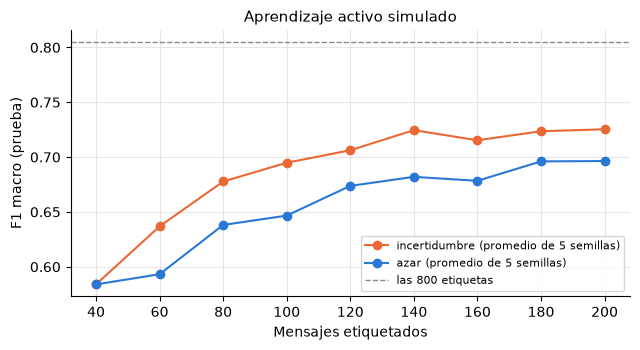

In [11]:
## Aprendizaje activo simulado: muestreo por incertidumbre frente a muestreo al azar
def curva(estrategia, semilla):
    rng = np.random.default_rng(semilla)
    etiquetados = list(rng.choice(len(y_train), size=40, replace=False))
    puntos = []
    for ronda in range(9):
        modelo = modelo_tfidf().fit(R_train[etiquetados], y_train[etiquetados])
        puntos.append((len(etiquetados), f1_score(y_test, modelo.predict(R_test), average="macro")))
        if ronda == 8:
            break
        pendientes = np.setdiff1d(np.arange(len(y_train)), etiquetados)
        if estrategia == "incertidumbre":
            prob = modelo.predict_proba(R_train[pendientes])[:, 1]
            nuevos = pendientes[np.argsort(np.abs(prob - 0.5))[:20]]
        else:
            nuevos = rng.choice(pendientes, size=20, replace=False)
        etiquetados += list(nuevos)
    return pd.DataFrame(puntos, columns=["etiquetas", "F1 macro"])


fig, ax = plt.subplots(figsize=(6.5, 3.6))
for estrategia, color in [("incertidumbre", NARANJA), ("azar", AZUL)]:
    curvas = pd.concat([curva(estrategia, 86 + s).assign(semilla=s) for s in range(5)])
    media = curvas.groupby("etiquetas")["F1 macro"].mean()
    ax.plot(media.index, media.values, "o-", color=color, label=f"{estrategia} (promedio de 5 semillas)")
ax.axhline(resultados[0]["F1 macro, protestas (prueba)"], color=GRIS, ls="--", lw=1, label="las 800 etiquetas")
ax.set(xlabel="Mensajes etiquetados", ylabel="F1 macro (prueba)", title="Aprendizaje activo simulado")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

**Para recordar.**
- Con el mismo número de etiquetas, elegir los mensajes **inciertos** suele rendir más que elegirlos al azar: cada etiqueta aporta más información.
- Es una forma de **ahorrar trabajo de codificación**: la persona etiqueta lo que el modelo no sabe. La sesión de hoy muestra otra: usar un LLM como anotador (notebook 6), validado contra codificación humana.

## 4. Ejercicios

1. **Normalizar o no.** Repitan la sección 2.2 con los mensajes normalizados de S12 (menciones como `@usuario`). ¿Cambia el F1 en la Convención? ¿Por qué podría importar con qué textos se ajustó el modelo?
2. **La Convención completa.** Cambien `N_CONVENCION = 1000` y repitan la comparación de la sección 2.2. ¿Se mantiene el orden de los modelos?
3. **Un umbral intermedio.** Prueben el auto-entrenamiento con `threshold=0.9` y con `criterion="k_best"`. ¿Cuántas pseudo-etiquetas agrega y qué tan correctas son?
4. **Aprendizaje activo con más rondas.** Extiendan la simulación de la sección 3.2 a 15 rondas. ¿Cuántas etiquetas hacen falta para acercarse al modelo con las 800?

**Para recordar (síntesis).**
- Los modelos tipo BERT ya ajustados se usan con pocas líneas de código, pero hay que saber **con qué se ajustaron**: si vieron sus datos de prueba, su desempeño está inflado.
- La validación **fuera del dominio** y contra la **codificación humana** es la que dice si un modelo sirve.
- El semi-supervisado no es gratis: puede empeorar el modelo. El aprendizaje activo ayuda a gastar mejor el presupuesto de etiquetado.

**Referencias**
- Cañete, J., Chaperon, G., Fuentes, R., Ho, J.-H., Kang, H. y Pérez, J. (2020). Spanish pre-trained BERT model and evaluation data. *PML4DC at ICLR 2020*.
- Devlin, J., Chang, M.-W., Lee, K. y Toutanova, K. (2019). BERT: Pre-training of deep bidirectional transformers for language understanding. *Proceedings of NAACL-HLT 2019*, 4171–4186.
- González-Bustamante, B. (2024). Benchmarking LLMs in political content text-annotation: Proof-of-concept with toxicity and incivility data. arXiv:2409.09741.
- Liu, Y. et al. (2019). RoBERTa: A robustly optimized BERT pretraining approach. arXiv:1907.11692.
- Settles, B. (2009). *Active learning literature survey* (Computer Sciences Technical Report 1648). University of Wisconsin–Madison.
- van Engelen, J. E. y Hoos, H. H. (2020). A survey on semi-supervised learning. *Machine Learning*, 109(2), 373–440.